# Comptage de mots : Python simple vs pseudo-MapReduce vs Hadoop MapReduce

## 0. Introduction et objectifs

Nous comparons trois implémentations du comptage d'occurrences de mots :
1. Python séquentiel (dictionnaire) ;
2. Pseudo-MapReduce en Python (map → shuffle → reduce en local) ;
3. Hadoop MapReduce (pseudo-distribué, HDFS + YARN).

**Hypothèses à tester :**
    
- H1 : sur petits fichiers, Python est plus rapide car Hadoop paie un coût fixe de démarrage.
- H2 : le temps de Hadoop croît moins vite avec la taille, d'où un éventuel point de bascule.
- H3 : la version pseudo-MapReduce consomme plus de mémoire (stockage de toutes les paires).

In [1]:
# Configuration du projet : dossier de travail fixé explicitement
import os
from pathlib import Path

PROJET = Path.home() / "tp_wordcount"
os.chdir(PROJET)
for dossier in ["data", "src", "results"]:
    (PROJET / dossier).mkdir(exist_ok=True)

print("Dossier de travail :", os.getcwd())
print("Contenu :", sorted(os.listdir()))

Dossier de travail : /home/fadwa_hdd/tp_wordcount
Contenu : ['.git', '.gitignore', '.ipynb_checkpoints', '.venv', 'data', 'requirements.txt', 'results', 'src', 'wordcount_comparaison.ipynb']


In [2]:
import platform, sys, subprocess, psutil

def cmd(c):
    """Exécute une commande shell et renvoie la première ligne de sa sortie."""
    try:
        r = subprocess.run(c, shell=True, capture_output=True, text=True)
        out = (r.stdout or r.stderr).strip()
        return out.splitlines()[0] if out else "non trouvé"
    except Exception as e:
        return f"indisponible ({e})"

print("OS        :", platform.platform())
print("Python    :", sys.version.split()[0])
print("CPU       :", cmd("grep -m1 'model name' /proc/cpuinfo").split(":")[-1].strip())
print("Cœurs     :", psutil.cpu_count(logical=False), "physiques /", psutil.cpu_count(), "logiques")
print("RAM       :", round(psutil.virtual_memory().total / 1e9, 1), "Go")
print("Disque    :", round(psutil.disk_usage('/').free / 1e9, 1), "Go libres")
print("Java      :", cmd("java -version"))
print("Hadoop    :", cmd("hadoop version"))

OS        : Linux-6.18.54.1-microsoft-standard-WSL2-x86_64-with-glibc2.35
Python    : 3.10.12
CPU       : 12th Gen Intel(R) Core(TM) i5-1235U
Cœurs     : 6 physiques / 12 logiques
RAM       : 8.2 Go
Disque    : 1017.4 Go libres
Java      : openjdk version "11.0.32.1" 2026-08-18
Hadoop    : /bin/sh: 1: hadoop: not found


In [3]:
print("Espace libre réel (C:) :", round(psutil.disk_usage('/mnt/c').free / 1e9, 1), "Go")

Espace libre réel (C:) : 77.2 Go


**Remarques sur l'environnement :**
- Tout s'exécute dans WSL2 (Ubuntu 22.04), sur le système de fichiers Linux, pour éviter le coût d'accès à `/mnt/c`.
- Python 3.10 (le document utilise 3.11 : sans impact ici). Java 11, version validée pour Hadoop 3.4.
- CPU hybride de portable (i5-1235U) : mesures faites sur secteur, en mode performances, et répétées pour lisser la variabilité.
- 8,2 Go de RAM alloués à WSL : c'est cette limite qui borne la taille des fichiers testés.
- « hadoop: not found » est attendu à ce stade : les variables Hadoop ne sont définies dans le notebook qu'en section 5.

## 2. Génération des données

- Vocabulaire : les 15 mots du document de référence, tirés selon une distribution de type Zipf (poids 1/rang), plus réaliste qu'un tirage uniforme.
- Graine aléatoire fixée pour la reproductibilité.
- Fichier de base : N = 100 000 lignes, un mot par ligne.
- Fichiers dérivés : le fichier de base dupliqué m fois, pour m ∈ {1, 5, 10, 50, 100, 200, 500}.

La duplication donne une **vérité terrain exacte** : compte attendu = compte dans le fichier de base × m. Chaque méthode sera validée contre cette référence avant toute mesure de temps.

In [4]:
import random
from pathlib import Path
from collections import Counter

DATA = Path("data")
DATA.mkdir(exist_ok=True)

VOCAB = ["chat", "chien", "arbre", "fleur", "maison", "soleil", "montagne", "livre",
         "ciel", "mer", "lune", "route", "oiseau", "jardin", "voiture"]
N = 100_000
SEED = 42

# Distribution de type Zipf : le mot de rang r a un poids 1/r
poids = [1 / (r + 1) for r in range(len(VOCAB))]
rng = random.Random(SEED)
mots = rng.choices(VOCAB, weights=poids, k=N)

base = DATA / f"base_N{N}.txt"
base.write_text("\n".join(mots) + "\n", encoding="utf-8")

ref_base = Counter(mots)   # vérité terrain pour m = 1
print(f"{base} : {N} lignes, {base.stat().st_size / 1e6:.2f} Mo")
print("Les 5 mots les plus fréquents :", ref_base.most_common(5))

data/base_N100000.txt : 100000 lignes, 0.59 Mo
Les 5 mots les plus fréquents : [('chat', 30137), ('chien', 15038), ('arbre', 10000), ('fleur', 7455), ('maison', 6103)]


In [5]:
import time
import pandas as pd

M_VALUES = [1, 5, 10, 50, 100, 200, 500]
contenu = base.read_bytes()   # environ 0,6 Mo, lu une seule fois

fichiers = {}
lignes_tab = []
for m in M_VALUES:
    f = DATA / f"mots_m{m}.txt"
    t0 = time.perf_counter()
    if not f.exists():                 # ne régénère pas si le fichier existe déjà
        with open(f, "wb") as out:
            for _ in range(m):         # écriture en flux : pas de copie géante en mémoire
                out.write(contenu)
    fichiers[m] = f
    lignes_tab.append({"m": m,
                       "lignes": N * m,
                       "taille (Mo)": round(f.stat().st_size / 1e6, 1),
                       "génération (s)": round(time.perf_counter() - t0, 2)})

df_fichiers = pd.DataFrame(lignes_tab)
df_fichiers

,m,lignes,taille (Mo),génération (s)
0,1,100000,0.6,0.0
1,5,500000,3.0,0.0
2,10,1000000,5.9,0.0
3,50,5000000,29.5,0.0
4,100,10000000,59.1,0.0
5,200,20000000,118.1,0.0
6,500,50000000,295.4,0.0


In [6]:
def reference(m):
    """Résultat attendu pour le fichier dupliqué m fois."""
    return {mot: n * m for mot, n in ref_base.items()}

def verifier(resultat, m):
    """Vérifie qu'un résultat est exactement égal à la vérité terrain."""
    attendu = reference(m)
    if dict(resultat) != attendu:
        diff = {k: (resultat.get(k), attendu.get(k))
                for k in set(resultat) | set(attendu)
                if resultat.get(k) != attendu.get(k)}
        raise AssertionError(f"Résultat incorrect pour m={m} : {diff}")
    return True

# Contrôle indépendant avec wc -l (outil système, pas notre code)
import subprocess
for m in [1, 500]:
    n_lignes = int(subprocess.run(["wc", "-l", str(fichiers[m])],
                                  capture_output=True, text=True).stdout.split()[0])
    assert n_lignes == N * m, f"m={m} : {n_lignes} lignes au lieu de {N * m}"
print("Nombre de lignes vérifié avec wc -l ✔")

Nombre de lignes vérifié avec wc -l ✔


## 3. Version 1 : Python simple

### Protocole de mesure (commun aux trois versions)
- Chaque exécution est lancée dans un processus séparé, comme en ligne de commande. Le temps mesuré inclut donc le démarrage de l'interpréteur, de même que le temps Hadoop inclut celui de la JVM.
- Une exécution d'échauffement valide le résultat contre la vérité terrain et met le fichier en cache disque. Toutes les méthodes sont ainsi mesurées à cache chaud.
- 5 répétitions : on retient la médiane (et on note le min et le max).
- Pic mémoire mesuré avec `/usr/bin/time` (RSS maximal).
- Limite mémoire de 6,5 Go pour les scripts Python, pour que le dépassement donne une `MemoryError` propre plutôt qu'un blocage de WSL.

### Implémentation
Code identique au document. Seule modification : le nom du fichier est passé en argument au lieu d'être écrit en dur.

In [7]:
%%writefile src/wordcount_v1.py
"""Version 1 : comptage séquentiel avec un dictionnaire (fidèle au document)."""
import sys

def compter_occurrences(fichier):
    with open(fichier, 'r', encoding='utf-8') as f:
        mots = f.read().split()
    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1
    return compteur

if __name__ == "__main__":
    fichier = sys.argv[1] if len(sys.argv) > 1 else "mots.txt"
    resultats = compter_occurrences(fichier)
    for mot, nb in sorted(resultats.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {nb}")

Overwriting src/wordcount_v1.py


In [8]:
import subprocess, sys, time, resource, statistics
from pathlib import Path

RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
LIMITE_MEMOIRE = int(6.5e9)   # octets

def _limiter_memoire():
    """Appliquée au processus enfant : au-delà de la limite, Python lève MemoryError."""
    resource.setrlimit(resource.RLIMIT_AS, (LIMITE_MEMOIRE, LIMITE_MEMOIRE))

def executer(cmd, limiter=True):
    """Lance cmd dans un processus séparé.
    Renvoie (durée en s, pic mémoire en Mo, stdout, code retour, stderr)."""
    t0 = time.perf_counter()
    r = subprocess.run(["/usr/bin/time", "-f", "%M"] + cmd,
                       capture_output=True, text=True,
                       preexec_fn=_limiter_memoire if limiter else None)
    duree = time.perf_counter() - t0
    try:
        pic_mo = int(r.stderr.strip().splitlines()[-1]) / 1024   # %M est en Ko
    except (ValueError, IndexError):
        pic_mo = float("nan")
    return duree, pic_mo, r.stdout, r.returncode, r.stderr

def parser_sortie(stdout):
    """Convertit les lignes 'mot : nb' en dictionnaire."""
    resultat = {}
    for ligne in stdout.strip().splitlines():
        mot, nb = ligne.rsplit(":", 1)
        resultat[mot.strip()] = int(nb)
    return resultat

def benchmark(nom, cmd_pour, m_values, repetitions=5):
    """Échauffement et validation, puis `repetitions` mesures, pour chaque m."""
    lignes = []
    for m in m_values:
        cmd = cmd_pour(fichiers[m])

        # 1) Échauffement et validation du résultat
        duree, pic, out, rc, err = executer(cmd)
        if rc != 0:
            statut = "échec mémoire" if "MemoryError" in err else f"échec (code {rc})"
            print(f"[{nom}] m={m:>4} : {statut}")
            lignes.append({"methode": nom, "m": m, "lignes": N * m, "statut": statut})
            break   # inutile de tester des fichiers plus gros
        verifier(parser_sortie(out), m)

        # 2) Mesures
        temps, pics = [], []
        for _ in range(repetitions):
            duree, pic, out, rc, err = executer(cmd)
            temps.append(duree)
            pics.append(pic)

        lignes.append({"methode": nom, "m": m, "lignes": N * m,
                       "taille_Mo": round(fichiers[m].stat().st_size / 1e6, 1),
                       "temps_median_s": round(statistics.median(temps), 4),
                       "temps_min_s": round(min(temps), 4),
                       "temps_max_s": round(max(temps), 4),
                       "memoire_pic_Mo": round(max(pics), 1),
                       "statut": "ok"})
        print(f"[{nom}] m={m:>4} : {statistics.median(temps):.3f} s (médiane), "
              f"{max(pics):.0f} Mo, résultat validé ✔")

    df = pd.DataFrame(lignes)
    df.to_csv(RESULTS / f"{nom}.csv", index=False)
    return df

In [9]:
temps_demarrage = statistics.median(
    executer([sys.executable, "-c", "pass"])[0] for _ in range(10)
)
print(f"Démarrage de l'interpréteur Python seul : {temps_demarrage * 1000:.1f} ms")

Démarrage de l'interpréteur Python seul : 17.5 ms


In [10]:
df_v1 = benchmark("v1_python_simple",
                  lambda f: [sys.executable, "src/wordcount_v1.py", str(f)],
                  M_VALUES)
df_v1

[v1_python_simple] m=   1 : 0.034 s (médiane), 16 Mo, résultat validé ✔
[v1_python_simple] m=   5 : 0.093 s (médiane), 45 Mo, résultat validé ✔
[v1_python_simple] m=  10 : 0.171 s (médiane), 83 Mo, résultat validé ✔
[v1_python_simple] m=  50 : 0.901 s (médiane), 434 Mo, résultat validé ✔
[v1_python_simple] m= 100 : 1.539 s (médiane), 754 Mo, résultat validé ✔
[v1_python_simple] m= 200 : 3.068 s (médiane), 1499 Mo, résultat validé ✔
[v1_python_simple] m= 500 : 8.610 s (médiane), 3735 Mo, résultat validé ✔


,methode,m,lignes,taille_Mo,temps_median_s,temps_min_s,temps_max_s,memoire_pic_Mo,statut
0,v1_python_simple,1,100000,0.6,0.0339,0.0308,0.0348,15.6,ok
1,v1_python_simple,5,500000,3.0,0.0935,0.0892,0.1093,45.4,ok
2,v1_python_simple,10,1000000,5.9,0.1707,0.1650,0.1795,82.7,ok
3,v1_python_simple,50,5000000,29.5,0.9012,0.8555,0.9120,434.4,ok
4,v1_python_simple,100,10000000,59.1,1.5393,1.4836,1.6687,753.7,ok
5,v1_python_simple,200,20000000,118.1,3.0681,2.9206,3.2834,1499.0,ok
6,v1_python_simple,500,50000000,295.4,8.6103,7.7078,9.1957,3735.3,ok


### Analyse de la V1
- **Démarrage :** l'interpréteur Python seul coûte 17,5 ms. Sur 100 000 mots, la V1 prend 34 ms, dont environ 16 ms de calcul. Le temps de 0,012 s mesuré dans le document correspondait donc surtout au lancement de Python.
- **Temps :** croissance linéaire, environ 150 à 180 ms par million de mots (8,6 s pour 50 M de mots), soit environ 6 M de mots/s.
- **Variabilité :** une première série de mesures, réalisée le matin sans les services Hadoop en arrière-plan, donnait jusqu'à 30 % de moins sur certains points (0,64 s au lieu de 0,90 s pour 5 M de mots). Seules les tendances fortes sont donc interprétées.
- **Mémoire :** environ 75 octets par mot (une chaîne Python par mot, un pointeur dans la liste, plus le texte brut lu d'un bloc), soit 3,7 Go pour 50 M de mots, conformément à l'estimation.
- **Facteur limitant :** le processeur. Le débit (environ 34 Mo/s) est très inférieur à la vitesse de lecture du cache.
- **Limite de passage à l'échelle :** `f.read().split()` charge tout le fichier en mémoire. Avec une limite de 6,5 Go, la V1 ne peut pas traiter plus d'environ 87 M de mots (6,5 Go / 75 o).

## 4. Version 2 : pseudo-MapReduce Python

Reproduction locale des trois phases du modèle :
- **map** : chaque ligne produit des paires `(mot, 1)` ;
- **shuffle** : les paires sont regroupées par clé (`mot → [1, 1, ...]`) ;
- **reduce** : les valeurs de chaque clé sont sommées.

Code identique au document. Seule modification : le nom du fichier est passé en argument.

**Prévision avant mesure :** la lecture se fait ligne par ligne, mais toutes les paires sont accumulées dans `mapped` avant le shuffle. Coût estimé : environ 140 octets par mot (chaîne, tuple, pointeur, puis entier dans la liste du shuffle), soit près de deux fois la V1. On prévoit donc un dépassement de la limite de 6,5 Go pour m = 500 (environ 7 Go) et un temps supérieur à celui de la V1.

In [11]:
%%writefile src/wordcount_v2.py
"""Version 2 : pseudo-MapReduce local (fidèle au document)."""
import sys
from collections import defaultdict

def mapper(ligne):
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]

def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped

def reducer(grouped_data):
    reduced = {}
    for mot, valeurs in grouped_data.items():
        reduced[mot] = sum(valeurs)
    return reduced

if __name__ == "__main__":
    fichier = sys.argv[1] if len(sys.argv) > 1 else "mots.txt"
    mapped = []
    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mapper(ligne))

    grouped = shuffle(mapped)
    reduced = reducer(grouped)

    for mot, count in sorted(reduced.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {count}")

Overwriting src/wordcount_v2.py


In [12]:
df_v2 = benchmark("v2_pseudo_mapreduce",
                  lambda f: [sys.executable, "src/wordcount_v2.py", str(f)],
                  M_VALUES)
df_v2

[v2_pseudo_mapreduce] m=   1 : 0.105 s (médiane), 23 Mo, résultat validé ✔
[v2_pseudo_mapreduce] m=   5 : 0.466 s (médiane), 78 Mo, résultat validé ✔
[v2_pseudo_mapreduce] m=  10 : 0.797 s (médiane), 147 Mo, résultat validé ✔
[v2_pseudo_mapreduce] m=  50 : 3.625 s (médiane), 698 Mo, résultat validé ✔
[v2_pseudo_mapreduce] m= 100 : 6.716 s (médiane), 1387 Mo, résultat validé ✔
[v2_pseudo_mapreduce] m= 200 : 14.995 s (médiane), 2766 Mo, résultat validé ✔
[v2_pseudo_mapreduce] m= 500 : échec mémoire


,methode,m,lignes,taille_Mo,temps_median_s,temps_min_s,temps_max_s,memoire_pic_Mo,statut
0,v2_pseudo_mapreduce,1,100000,0.6,0.1050,0.0900,0.1264,22.7,ok
1,v2_pseudo_mapreduce,5,500000,3.0,0.4658,0.4373,0.4973,78.0,ok
2,v2_pseudo_mapreduce,10,1000000,5.9,0.7974,0.6612,0.8817,146.9,ok
3,v2_pseudo_mapreduce,50,5000000,29.5,3.6247,2.9740,4.1471,698.3,ok
4,v2_pseudo_mapreduce,100,10000000,59.1,6.7161,6.4463,7.9055,1387.1,ok
5,v2_pseudo_mapreduce,200,20000000,118.1,14.9948,14.9351,15.4632,2765.7,ok
6,v2_pseudo_mapreduce,500,50000000,NaN,NaN,NaN,NaN,NaN,échec mémoire


### Analyse de la V2
- **H3 validée :** environ 138 octets par mot (prévision : 140), soit 1,8 fois la V1. Limite théorique : 6,5 Go / 138 o ≈ 47 M de mots, d'où la `MemoryError` à 50 M de mots, comme prévu.
- **Temps :** 4 à 5 fois plus lent que la V1 (15,0 s contre 3,1 s pour 20 M de mots). Causes : un appel de fonction par ligne, un tuple créé par mot, et deux passes supplémentaires (shuffle, puis reduce).
- **Correction du document :** la « surcharge faible » observée sur un petit fichier n'était qu'un effet du temps de démarrage. À l'échelle, la surcharge est d'un facteur 4 à 5.
- **Limite structurelle :** la V2 reproduit la *forme* du modèle MapReduce, mais pas ses *mécanismes de passage à l'échelle*. Toutes les paires intermédiaires restent en mémoire, alors que Hadoop les écrit sur disque (*spill*), les trie, et les réduit localement grâce à un *combiner* avant le shuffle.

## 5. Version 3 : Hadoop MapReduce

### Installation (réalisée dans le terminal WSL)
- **Hadoop 3.4.3** au lieu de 3.4.0 : même branche 3.4, même modèle MapReduce et même exemple WordCount (corrections de bugs uniquement). La 3.4.0 n'est plus servie que par le serveur d'archives d'Apache, très lent. La 3.4.3 est distribuée par le CDN et n'embarque pas le SDK AWS (environ 500 Mo inutiles ici).
- Intégrité de l'archive vérifiée par somme SHA-512.
- Java 11 (`JAVA_HOME` déclaré aussi dans `hadoop-env.sh`, car les scripts de démarrage passent par SSH).
- SSH sans mot de passe vers `localhost`, nécessaire aux scripts `start-dfs.sh` et `start-yarn.sh`. Correction préalable d'une option invalide dans `/etc/ssh/ssh_config`.
- **À chaque redémarrage de WSL :** relancer `sudo service ssh start` avant de démarrer Hadoop.

### Configuration pseudo-distribuée (écrite par le notebook)
- `dfs.replication = 1` (un seul nœud).
- Données HDFS dans `~/hadoop_data` plutôt que `/tmp`, qui est effacé à chaque redémarrage de WSL.
- YARN limité à 4 Go et conteneurs de 1 Go, adaptés aux 8,2 Go de RAM de WSL.
- Mémoire maximale des services Hadoop limitée à 512 Mo chacun.
- Contrôle de la mémoire virtuelle désactivé (faux positifs fréquents avec Java 11 sous WSL).

In [13]:
import os, subprocess
from pathlib import Path

JAVA_HOME   = "/usr/lib/jvm/java-11-openjdk-amd64"
HADOOP_HOME = Path.home() / "hadoop"
HADOOP_CONF = HADOOP_HOME / "etc" / "hadoop"
HADOOP_DATA = Path.home() / "hadoop_data"

os.environ["JAVA_HOME"] = JAVA_HOME
os.environ["HADOOP_HOME"] = str(HADOOP_HOME)
os.environ["HADOOP_CONF_DIR"] = str(HADOOP_CONF)
os.environ["PDSH_RCMD_TYPE"] = "ssh"
chemins = f"{HADOOP_HOME}/bin:{HADOOP_HOME}/sbin:{JAVA_HOME}/bin"
if chemins not in os.environ["PATH"]:
    os.environ["PATH"] = chemins + ":" + os.environ["PATH"]

print(subprocess.run(["hadoop", "version"], capture_output=True, text=True).stdout.splitlines()[0])

Hadoop 3.4.3


In [15]:
import shutil

def ecrire_xml(nom, proprietes):
    """Écrit un fichier de configuration Hadoop. L'original est sauvegardé une seule fois en .orig."""
    chemin = HADOOP_CONF / nom
    sauvegarde = chemin.with_suffix(".xml.orig")
    if chemin.exists() and not sauvegarde.exists():
        shutil.copy(chemin, sauvegarde)
    lignes = ['<?xml version="1.0" encoding="UTF-8"?>', "<configuration>"]
    for cle, valeur in proprietes.items():
        lignes += ["  <property>", f"    <name>{cle}</name>",
                   f"    <value>{valeur}</value>", "  </property>"]
    lignes.append("</configuration>")
    chemin.write_text("\n".join(lignes) + "\n")
    print(f"✔ {nom}")

ecrire_xml("core-site.xml", {
    "fs.defaultFS": "hdfs://localhost:9000",
    "hadoop.tmp.dir": f"{HADOOP_DATA}/tmp",
})

ecrire_xml("hdfs-site.xml", {
    "dfs.replication": "1",
    "dfs.namenode.name.dir": f"file://{HADOOP_DATA}/namenode",
    "dfs.datanode.data.dir": f"file://{HADOOP_DATA}/datanode",
})

ecrire_xml("mapred-site.xml", {
    "mapreduce.framework.name": "yarn",
    "mapreduce.application.classpath":
        "$HADOOP_MAPRED_HOME/share/hadoop/mapreduce/*:$HADOOP_MAPRED_HOME/share/hadoop/mapreduce/lib/*",
    "yarn.app.mapreduce.am.env": f"HADOOP_MAPRED_HOME={HADOOP_HOME}",
    "mapreduce.map.env":         f"HADOOP_MAPRED_HOME={HADOOP_HOME}",
    "mapreduce.reduce.env":      f"HADOOP_MAPRED_HOME={HADOOP_HOME}",
    "yarn.app.mapreduce.am.resource.mb": "1024",
    "mapreduce.map.memory.mb": "1024",
    "mapreduce.reduce.memory.mb": "1024",
})

ecrire_xml("yarn-site.xml", {
    "yarn.nodemanager.aux-services": "mapreduce_shuffle",
    "yarn.nodemanager.env-whitelist":
        "JAVA_HOME,HADOOP_COMMON_HOME,HADOOP_HDFS_HOME,HADOOP_CONF_DIR,"
        "CLASSPATH_PREPEND_DISTCACHE,HADOOP_YARN_HOME,HADOOP_HOME,PATH,LANG,TZ,HADOOP_MAPRED_HOME",
    "yarn.nodemanager.resource.memory-mb": "4096",
    "yarn.scheduler.minimum-allocation-mb": "512",
    "yarn.scheduler.maximum-allocation-mb": "4096",
    "yarn.nodemanager.vmem-check-enabled": "false",
})

# Mémoire maximale des services Hadoop (lue par hadoop-env.sh, car les services démarrent via SSH)
env_sh = HADOOP_CONF / "hadoop-env.sh"
contenu_env = env_sh.read_text()
for ligne in [f"export JAVA_HOME={JAVA_HOME}", "export HADOOP_HEAPSIZE_MAX=512m"]:
    if ligne not in contenu_env:
        with open(env_sh, "a") as f:
            f.write(ligne + "\n")
print("✔ hadoop-env.sh")

✔ core-site.xml
✔ hdfs-site.xml
✔ mapred-site.xml
✔ yarn-site.xml
✔ hadoop-env.sh


In [16]:
if not (HADOOP_DATA / "namenode" / "current").exists():
    r = subprocess.run(["hdfs", "namenode", "-format", "-nonInteractive"],
                       capture_output=True, text=True)
    print("\n".join((r.stdout + r.stderr).splitlines()[-5:]))
else:
    print("HDFS déjà formaté : formatage ignoré (il effacerait les données).")

HDFS déjà formaté : formatage ignoré (il effacerait les données).


In [17]:
import time

ATTENDUS = {"NameNode", "DataNode", "SecondaryNameNode", "ResourceManager", "NodeManager"}

def services_hadoop():
    """Renvoie l'ensemble des services Java actifs (d'après jps)."""
    sortie = subprocess.run(["jps"], capture_output=True, text=True).stdout
    return {l.split()[1] for l in sortie.splitlines() if len(l.split()) == 2}

if ATTENDUS <= services_hadoop():
    print("Hadoop déjà démarré : rien à faire.")
else:
    for script in ["start-dfs.sh", "start-yarn.sh"]:
        r = subprocess.run([script], stdin=subprocess.DEVNULL,
                           capture_output=True, text=True, timeout=120)
        print(f"$ {script}\n{r.stdout}{r.stderr}")
    time.sleep(5)   # laisse le temps aux services Java de démarrer

manquants = ATTENDUS - services_hadoop()
print("✔ Les 5 services Hadoop tournent" if not manquants else f"⚠ Services manquants : {manquants}")

$ start-dfs.sh
Starting namenodes on [localhost]
localhost: namenode is running as process 1045.  Stop it first and ensure /tmp/hadoop-fadwa_hdd-namenode.pid file is empty before retry.
Starting datanodes
localhost: datanode is running as process 1176.  Stop it first and ensure /tmp/hadoop-fadwa_hdd-datanode.pid file is empty before retry.
Starting secondary namenodes [FadwaUniv]
FadwaUniv: secondarynamenode is running as process 1417.  Stop it first and ensure /tmp/hadoop-fadwa_hdd-secondarynamenode.pid file is empty before retry.

$ start-yarn.sh
Starting resourcemanager
Starting nodemanagers
localhost: nodemanager is running as process 1770.  Stop it first and ensure /tmp/hadoop-fadwa_hdd-nodemanager.pid file is empty before retry.

✔ Les 5 services Hadoop tournent


### Protocole de mesure pour Hadoop
- Les fichiers sont copiés une fois dans HDFS. Le temps de copie est mesuré séparément (en usage réel, les données résident déjà dans HDFS).
- Temps mesuré : la commande `hadoop jar ... wordcount`, du lancement à la fin. Il inclut le démarrage des JVM, la soumission à YARN, les phases map et reduce, et l'écriture du résultat dans HDFS.
- Le dossier de sortie est supprimé avant chaque exécution, hors chronométrage.
- Échauffement avec validation contre la vérité terrain, puis 3 répétitions (médiane).
- Mémoire : relevée par les compteurs du job (pic mémoire par tâche), car Hadoop répartit le travail entre plusieurs JVM.
- Compteurs du combiner relevés pour expliquer le comportement mémoire.

In [18]:
import getpass, re

UTILISATEUR = getpass.getuser()
HDFS_BASE = f"/user/{UTILISATEUR}/wordcount"
JAR = next(HADOOP_HOME.glob("share/hadoop/mapreduce/hadoop-mapreduce-examples-*.jar"))

def hdfs(*args):
    """Lance une commande 'hdfs dfs ...'."""
    return subprocess.run(["hdfs", "dfs", *args], capture_output=True, text=True)

hdfs("-mkdir", "-p", f"{HDFS_BASE}/input")

lignes_upload = []
for m, f in fichiers.items():
    t0 = time.perf_counter()
    r = hdfs("-put", "-f", str(f), f"{HDFS_BASE}/input/{f.name}")
    duree = time.perf_counter() - t0
    if r.returncode != 0:
        raise RuntimeError(f"Échec de la copie de {f.name} :\n{r.stderr}")
    lignes_upload.append({"m": m, "taille_Mo": round(f.stat().st_size / 1e6, 1),
                          "copie_hdfs_s": round(duree, 2)})

print(hdfs("-ls", f"{HDFS_BASE}/input").stdout)
df_upload = pd.DataFrame(lignes_upload)
df_upload

Found 7 items
-rw-r--r--   1 fadwa_hdd supergroup     590719 2026-10-13 14:13 /user/fadwa_hdd/wordcount/input/mots_m1.txt
-rw-r--r--   1 fadwa_hdd supergroup    5907190 2026-10-13 14:13 /user/fadwa_hdd/wordcount/input/mots_m10.txt
-rw-r--r--   1 fadwa_hdd supergroup   59071900 2026-10-13 14:13 /user/fadwa_hdd/wordcount/input/mots_m100.txt
-rw-r--r--   1 fadwa_hdd supergroup  118143800 2026-10-13 14:13 /user/fadwa_hdd/wordcount/input/mots_m200.txt
-rw-r--r--   1 fadwa_hdd supergroup    2953595 2026-10-13 14:13 /user/fadwa_hdd/wordcount/input/mots_m5.txt
-rw-r--r--   1 fadwa_hdd supergroup   29535950 2026-10-13 14:13 /user/fadwa_hdd/wordcount/input/mots_m50.txt
-rw-r--r--   1 fadwa_hdd supergroup  295359500 2026-10-13 14:13 /user/fadwa_hdd/wordcount/input/mots_m500.txt



,m,taille_Mo,copie_hdfs_s
0,1,0.6,3.62
1,5,3.0,2.07
2,10,5.9,2.06
3,50,29.5,3.18
4,100,59.1,3.37
5,200,118.1,3.07
6,500,295.4,2.93


In [19]:
COMPTEURS = ["Launched map tasks", "Map output records",
             "Combine input records", "Combine output records", "Reduce input records",
             "Peak Map Physical memory (bytes)", "Peak Reduce Physical memory (bytes)"]

def lire_compteurs(log):
    """Extrait les compteurs du job depuis le journal de 'hadoop jar'."""
    c = {}
    for nom in COMPTEURS:
        trouve = re.search(re.escape(nom) + r"=(\d+)", log)
        if trouve:
            c[nom] = int(trouve.group(1))
    return c

def lire_sortie_hdfs(dossier):
    """Lit le résultat du job (lignes 'mot<TAB>nb') et le convertit en dictionnaire."""
    r = hdfs("-cat", f"{dossier}/part-r-*")
    resultat = {}
    for ligne in r.stdout.strip().splitlines():
        mot, nb = ligne.split("\t")
        resultat[mot] = int(nb)
    return resultat

def executer_hadoop(m):
    """Supprime l'ancienne sortie (non chronométré), puis lance et chronomètre le job."""
    entree = f"{HDFS_BASE}/input/{fichiers[m].name}"
    sortie = f"{HDFS_BASE}/output/m{m}"
    hdfs("-rm", "-r", "-f", "-skipTrash", sortie)
    t0 = time.perf_counter()
    r = subprocess.run(["hadoop", "jar", str(JAR), "wordcount", entree, sortie],
                       capture_output=True, text=True)
    duree = time.perf_counter() - t0
    return duree, r, sortie

In [20]:
duree, r, sortie = executer_hadoop(1)
print(f"Code retour : {r.returncode}   Durée : {duree:.1f} s")

if r.returncode != 0:
    print(r.stderr[-3000:])          # fin du journal, pour diagnostiquer
else:
    resultat = lire_sortie_hdfs(sortie)
    print("Résultat :", dict(sorted(resultat.items(), key=lambda x: -x[1])))
    verifier(resultat, 1)
    print("Résultat validé contre la vérité terrain ✔")
    for nom, val in lire_compteurs(r.stderr).items():
        print(f"  {nom:<38} {val:>12,}")

Code retour : 0   Durée : 28.8 s
Résultat : {'chat': 30137, 'chien': 15038, 'arbre': 10000, 'fleur': 7455, 'maison': 6103, 'soleil': 5003, 'montagne': 4375, 'livre': 3837, 'ciel': 3353, 'mer': 2968, 'lune': 2641, 'route': 2560, 'oiseau': 2308, 'jardin': 2197, 'voiture': 2025}
Résultat validé contre la vérité terrain ✔
  Launched map tasks                                1
  Map output records                          100,000
  Combine input records                       100,000
  Combine output records                           15
  Reduce input records                             15
  Peak Map Physical memory (bytes)        335,503,360
  Peak Reduce Physical memory (bytes)     243,380,224


In [21]:
# Rechargement des mesures V1 et V2 (évite de relancer les benchmarks Python)
df_v1 = pd.read_csv(RESULTS / "v1_python_simple.csv")
df_v2 = pd.read_csv(RESULTS / "v2_pseudo_mapreduce.csv")
print(f"V1 : {len(df_v1)} lignes, V2 : {len(df_v2)} lignes rechargées")

V1 : 7 lignes, V2 : 7 lignes rechargées


In [22]:
def benchmark_hadoop(m_values, repetitions=3, nom="v3_hadoop"):
    """Même protocole que pour Python : échauffement et validation, puis répétitions."""
    lignes = []
    for m in m_values:
        duree, r, sortie = executer_hadoop(m)          # échauffement
        if r.returncode != 0:
            print(f"[{nom}] m={m:>4} : échec\n{r.stderr[-1500:]}")
            lignes.append({"methode": nom, "m": m, "lignes": N * m, "statut": "échec"})
            break
        verifier(lire_sortie_hdfs(sortie), m)

        temps = []
        for _ in range(repetitions):
            duree, r, sortie = executer_hadoop(m)
            temps.append(duree)

        c = lire_compteurs(r.stderr)
        pic = max(c.get("Peak Map Physical memory (bytes)", 0),
                  c.get("Peak Reduce Physical memory (bytes)", 0)) / 2**20
        lignes.append({"methode": nom, "m": m, "lignes": N * m,
                       "taille_Mo": round(fichiers[m].stat().st_size / 1e6, 1),
                       "temps_median_s": round(statistics.median(temps), 2),
                       "temps_min_s": round(min(temps), 2),
                       "temps_max_s": round(max(temps), 2),
                       "memoire_pic_Mo": round(pic, 1),
                       "maps": c.get("Launched map tasks"),
                       "combine_entree": c.get("Combine input records"),
                       "combine_sortie": c.get("Combine output records"),
                       "statut": "ok"})
        print(f"[{nom}] m={m:>4} : {statistics.median(temps):.1f} s (médiane), "
              f"{c.get('Launched map tasks')} map(s), pic {pic:.0f} Mo/tâche, résultat validé ✔")

    df = pd.DataFrame(lignes)
    df.to_csv(RESULTS / f"{nom}.csv", index=False)
    return df

df_v3 = benchmark_hadoop(M_VALUES)
df_v3

[v3_hadoop] m=   1 : 22.7 s (médiane), 1 map(s), pic 323 Mo/tâche, résultat validé ✔
[v3_hadoop] m=   5 : 22.7 s (médiane), 1 map(s), pic 333 Mo/tâche, résultat validé ✔
[v3_hadoop] m=  10 : 22.6 s (médiane), 1 map(s), pic 363 Mo/tâche, résultat validé ✔
[v3_hadoop] m=  50 : 26.6 s (médiane), 1 map(s), pic 350 Mo/tâche, résultat validé ✔
[v3_hadoop] m= 100 : 28.7 s (médiane), 1 map(s), pic 416 Mo/tâche, résultat validé ✔
[v3_hadoop] m= 200 : 34.8 s (médiane), 1 map(s), pic 523 Mo/tâche, résultat validé ✔
[v3_hadoop] m= 500 : 44.9 s (médiane), 3 map(s), pic 392 Mo/tâche, résultat validé ✔


,methode,m,lignes,taille_Mo,temps_median_s,temps_min_s,temps_max_s,memoire_pic_Mo,maps,combine_entree,combine_sortie,statut
0,v3_hadoop,1,100000,0.6,22.73,22.46,23.77,323.2,1,100000,15,ok
1,v3_hadoop,5,500000,3.0,22.74,21.70,23.62,332.5,1,500000,15,ok
2,v3_hadoop,10,1000000,5.9,22.60,22.34,24.88,363.2,1,1000000,15,ok
3,v3_hadoop,50,5000000,29.5,26.60,25.51,26.68,349.5,1,5000000,30,ok
4,v3_hadoop,100,10000000,59.1,28.73,28.50,32.57,415.7,1,10000060,75,ok
5,v3_hadoop,200,20000000,118.1,34.82,33.55,35.63,523.4,1,20000105,120,ok
6,v3_hadoop,500,50000000,295.4,44.94,41.95,52.45,391.8,3,50000240,300,ok


### Analyse de la V3
- **Coût fixe élevé :** environ 22,6 s jusqu'à 1 M de mots, quelle que soit la taille. Ce temps correspond au démarrage des JVM (client, maître d'application, tâches), à la planification par YARN et aux écritures HDFS : environ 1 300 fois le démarrage de Python.
- **Coût marginal :** environ 0,64 s par million de mots tant qu'une seule tâche map traite le fichier (jusqu'à 20 M de mots, soit 118 Mo). À 50 M de mots, le fichier occupe 3 blocs HDFS de 128 Mo, traités par 3 maps en parallèle : le coût marginal tombe à environ 0,34 s par million.
- **Mémoire bornée :** 320 à 520 Mo par tâche, sans lien avec la taille totale du fichier. À 50 M de mots, le pic redescend même à 392 Mo, car chaque map ne traite qu'un bloc. La mémoire dépend de la taille d'un bloc, pas de celle des données.
- **Combiner :** chaque map émet une paire `(mot, 1)` par mot, mais le combiner les réduit à 15 paires à chaque déversement du tampon de tri sur disque (*spill*). On passe ainsi de 15 paires jusqu'à 1 M de mots à 300 pour 50 M de mots. Le reduce reçoit quelques centaines d'enregistrements au lieu de dizaines de millions : c'est exactement le mécanisme qui manque à la V2.
- **Copie dans HDFS :** 2 à 3,6 s quelle que soit la taille du fichier, temps dominé par le démarrage de la JVM du client.

## 6. Comparaison des trois méthodes

Mêmes fichiers, même protocole (échauffement avec validation, répétitions, médiane).
Remarque sur la mémoire : pour Python, il s'agit du pic du processus unique. Pour Hadoop, du pic d'une tâche (map ou reduce), chacune s'exécutant dans son propre conteneur YARN de 1 Go.

In [23]:
df_all = pd.concat([df_v1, df_v2, df_v3], ignore_index=True)
df_all.to_csv(RESULTS / "comparaison.csv", index=False)

ok = df_all[df_all["statut"] == "ok"]
tableau_temps = ok.pivot(index="lignes", columns="methode", values="temps_median_s")
tableau_mem   = ok.pivot(index="lignes", columns="methode", values="memoire_pic_Mo")
tableau_temps["Hadoop / V1"] = (tableau_temps["v3_hadoop"] / tableau_temps["v1_python_simple"]).round(1)

print("Temps médian (s)")
display(tableau_temps)
print("Pic mémoire (Mo)")
display(tableau_mem)

Temps médian (s)


methode,v1_python_simple,v2_pseudo_mapreduce,v3_hadoop,Hadoop / V1
lignes,,,,
100000,0.0339,0.1050,22.73,670.5
500000,0.0935,0.4658,22.74,243.2
1000000,0.1707,0.7974,22.60,132.4
5000000,0.9012,3.6247,26.60,29.5
10000000,1.5393,6.7161,28.73,18.7
20000000,3.0681,14.9948,34.82,11.3
50000000,8.6103,NaN,44.94,5.2


Pic mémoire (Mo)


methode,v1_python_simple,v2_pseudo_mapreduce,v3_hadoop
lignes,,,
100000,15.6,22.7,323.2
500000,45.4,78.0,332.5
1000000,82.7,146.9,363.2
5000000,434.4,698.3,349.5
10000000,753.7,1387.1,415.7
20000000,1499.0,2765.7,523.4
50000000,3735.3,NaN,391.8


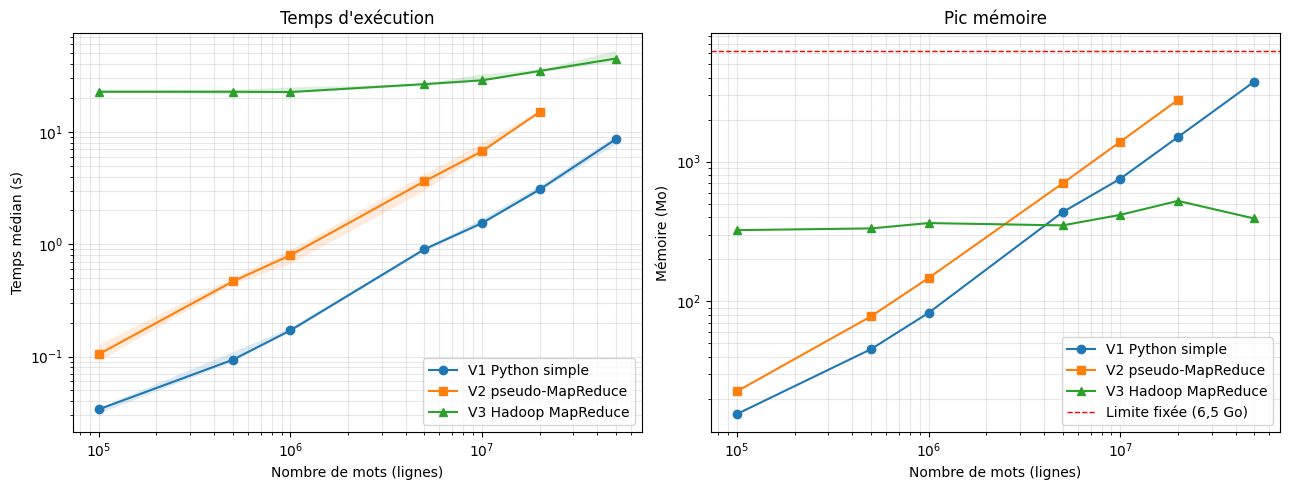

In [24]:
import matplotlib.pyplot as plt

STYLE = {"v1_python_simple":    ("V1 Python simple", "o-"),
         "v2_pseudo_mapreduce": ("V2 pseudo-MapReduce", "s-"),
         "v3_hadoop":           ("V3 Hadoop MapReduce", "^-")}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for methode, (label, style) in STYLE.items():
    d = ok[ok["methode"] == methode]
    ax1.plot(d["lignes"], d["temps_median_s"], style, label=label)
    ax1.fill_between(d["lignes"], d["temps_min_s"], d["temps_max_s"], alpha=0.15)
    ax2.plot(d["lignes"], d["memoire_pic_Mo"], style, label=label)

ax2.axhline(LIMITE_MEMOIRE / 2**20, color="red", ls="--", lw=1, label="Limite fixée (6,5 Go)")
for ax, titre, ylabel in [(ax1, "Temps d'exécution", "Temps médian (s)"),
                          (ax2, "Pic mémoire", "Mémoire (Mo)")]:
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Nombre de mots (lignes)"); ax.set_ylabel(ylabel)
    ax.set_title(titre); ax.grid(True, which="both", alpha=0.3); ax.legend()

plt.tight_layout()
plt.savefig(RESULTS / "comparaison.png", dpi=150)
plt.show()

In [25]:
import numpy as np

print(f"{'Méthode':<22}{'Coût fixe (s)':>15}{'Coût par M de mots (s)':>25}")
modeles = {}
for methode, (label, _) in STYLE.items():
    d = ok[ok["methode"] == methode]
    pente, fixe = np.polyfit(d["lignes"], d["temps_median_s"], 1)   # t = fixe + pente × n
    modeles[methode] = (fixe, pente)
    print(f"{label:<22}{fixe:>15.2f}{pente * 1e6:>25.3f}")

(f1, p1), (fh, ph) = modeles["v1_python_simple"], modeles["v3_hadoop"]
if ph < p1:
    n_bascule = (fh - f1) / (p1 - ph)
    print(f"\nPoint de bascule estimé V1/Hadoop : environ {n_bascule / 1e6:.0f} M de mots "
          f"(environ {n_bascule * 5.9 / 1e9:.1f} Go)")
    print(f"Limite mémoire de la V1 (environ 75 o/mot, 6,5 Go) : environ {6.5e9 / 75 / 1e6:.0f} M de mots")
else:
    print("\nHadoop a un coût par mot supérieur à la V1 sur cette machine : pas de point de bascule en vitesse.")

Méthode                 Coût fixe (s)   Coût par M de mots (s)
V1 Python simple                -0.05                    0.171
V2 pseudo-MapReduce             -0.05                    0.737
V3 Hadoop MapReduce             23.41                    0.454

Hadoop a un coût par mot supérieur à la V1 sur cette machine : pas de point de bascule en vitesse.


### Analyse comparative
- **Petits fichiers (H1 validée) :** sur 100 000 mots, Hadoop est 670 fois plus lent que la V1 (22,7 s contre 0,034 s). Son temps est presque entièrement du coût fixe.
- **L'écart se réduit sans s'inverser (H2 partiellement validée) :** le rapport Hadoop/V1 passe de 670 à 5,2 entre 0,1 et 50 M de mots, car le coût fixe de Hadoop est amorti. Mais son coût par mot reste supérieur : le modèle linéaire donne 0,45 s par million de mots pour Hadoop, contre 0,17 s pour la V1. **Sur cette machine, il n'y a pas de point de bascule en vitesse.**
- **Pourquoi Hadoop reste plus lent par mot ici :**
  - le parallélisme est plafonné : un seul nœud, et la configuration YARN (4 Go) n'autorise que 3 maps simultanés à côté du maître d'application ;
  - chaque enregistrement subit des surcoûts (sérialisation, tri, déversements sur disque, lecture et écriture HDFS), superflus pour 15 clés distinctes qu'un dictionnaire Python traite directement en mémoire ;
  - aucun des avantages d'un vrai cluster ne s'applique (plusieurs disques et plusieurs machines, calcul placé près des données).
- **Mémoire :** la V1 et la V2 croissent linéairement (75 et 138 octets par mot), alors que Hadoop reste plafonné à environ 0,3 à 0,5 Go par tâche.
- *Remarque :* l'ajustement linéaire mélange des régimes différents (1 map, puis 3). Il donne un ordre de grandeur, pas une loi précise.

## 7. Au-delà de la limite mémoire de Python
Test sur des fichiers plus gros (m = 1000 et 2000, soit 100 et 200 M de mots) : une seule exécution par méthode et par taille. La V2 n'est pas testée, car elle échouait déjà à m = 500.

In [26]:
LIMITE_MEMOIRE = int(4.5e9)   # Hadoop occupe environ 2 Go : on abaisse la limite pour protéger WSL

lignes_ext = []
for m in [1000, 2000]:
    f = DATA / f"mots_m{m}.txt"
    if not f.exists():
        with open(f, "wb") as out:
            for _ in range(m):
                out.write(contenu)
    fichiers[m] = f
    hdfs("-put", "-f", str(f), f"{HDFS_BASE}/input/{f.name}")

    # V1 : une exécution
    d1, pic1, out1, rc1, err1 = executer([sys.executable, "src/wordcount_v1.py", str(f)])
    statut1 = "ok" if rc1 == 0 and verifier(parser_sortie(out1), m) else \
              ("échec mémoire" if "MemoryError" in err1 else f"échec ({rc1})")

    # Hadoop : une exécution
    dh, r, sortie = executer_hadoop(m)
    statuth = "ok" if r.returncode == 0 and verifier(lire_sortie_hdfs(sortie), m) else "échec"
    c = lire_compteurs(r.stderr)

    lignes_ext.append({"m": m, "lignes": N * m, "taille_Mo": round(f.stat().st_size / 1e6),
                       "V1 temps (s)": round(d1, 1) if statut1 == "ok" else None, "V1 statut": statut1,
                       "Hadoop temps (s)": round(dh, 1), "Hadoop maps": c.get("Launched map tasks"),
                       "Hadoop statut": statuth})
    print(lignes_ext[-1])

df_ext = pd.DataFrame(lignes_ext)
df_ext.to_csv(RESULTS / "extension.csv", index=False)
df_ext

{'m': 1000, 'lignes': 100000000, 'taille_Mo': 591, 'V1 temps (s)': None, 'V1 statut': 'échec mémoire', 'Hadoop temps (s)': 81.0, 'Hadoop maps': 6, 'Hadoop statut': 'ok'}
{'m': 2000, 'lignes': 200000000, 'taille_Mo': 1181, 'V1 temps (s)': None, 'V1 statut': 'échec mémoire', 'Hadoop temps (s)': 139.6, 'Hadoop maps': 10, 'Hadoop statut': 'ok'}


,m,lignes,taille_Mo,V1 temps (s),V1 statut,Hadoop temps (s),Hadoop maps,Hadoop statut
0,1000,100000000,591,None,échec mémoire,81.0,6,ok
1,2000,200000000,1181,None,échec mémoire,139.6,10,ok


### Analyse : au-delà de la limite mémoire
- **La V1 échoue à 100 et 200 M de mots :** il lui faudrait environ 7,5 et 15 Go (75 octets par mot), soit plus que toute la RAM de WSL. La limite a été abaissée à 4,5 Go pour ce test, car les services Hadoop occupaient de la mémoire, mais l'échec était de toute façon inévitable.
- **Hadoop traite 100 M de mots en 81 s (6 maps) et 200 M de mots (1,2 Go) en 140 s (10 maps),** sans changer de configuration, avec des résultats validés.
- **Le coût marginal remonte à environ 0,6 à 0,7 s par million de mots :** avec 3 maps simultanés au maximum, les 6 ou 10 maps s'exécutent en plusieurs vagues, chacune payant le démarrage de ses conteneurs.
- **Le vrai point de bascule est un point de faisabilité :** au-delà d'environ 90 M de mots (environ 0,5 Go de texte) sur cette machine, les versions Python du document ne produisent plus de résultat. Hadoop, si.

## 8. Conclusion

### Bilan des hypothèses

| Hypothèse | Verdict | Élément déterminant |
|---|---|---|
| H1 : Python plus rapide sur petits fichiers | **Validée** | Coût fixe de 22,6 s pour Hadoop contre 17,5 ms pour Python ; Hadoop 670 fois plus lent sur 100 000 mots |
| H2 : Hadoop croît moins vite, d'où un point de bascule | **Partiellement validée** | Le rapport Hadoop/V1 passe de 670 à 5,2 grâce à l'amortissement du coût fixe, mais le coût par mot de Hadoop reste supérieur sur une seule machine : pas de bascule en vitesse |
| H3 : la V2 consomme plus de mémoire | **Validée** | 138 octets par mot contre 75 pour la V1 ; échec mémoire à 50 M de mots, comme prévu |

### Ce que ce travail corrige dans le document de référence
- Les temps de 0,012 s et 0,017 s mesuraient surtout le démarrage de l'interpréteur. Sur des fichiers de taille significative, la V2 est 4 à 5 fois plus lente que la V1, et non « faiblement » plus lente.
- L'affirmation selon laquelle Hadoop devient plus performant au-delà de quelques gigaoctets n'est pas vérifiée en mode pseudo-distribué. Sur un seul portable, Hadoop reste environ 4 fois plus lent par mot que la V1, même à 200 M de mots (1,4 contre 6 M de mots/s). Cette affirmation suppose un vrai cluster.

### Ce que Hadoop apporte réellement
Sur une seule machine, Hadoop ne gagne pas en **vitesse**, il gagne en **capacité**. Le découpage en blocs, le déversement sur disque et le combiner bornent la mémoire de chaque tâche, quelle que soit la taille des données. Hadoop traite ainsi 200 M de mots, alors que les versions Python du document échouent dès 50 M (V2) et 100 M de mots (V1). Sur un cluster, le même modèle répartit en plus le calcul et le stockage entre plusieurs machines : c'est là que le gain en vitesse devient possible.

### Limites de l'étude
- Une seule machine (WSL2 sur un portable) : aucun parallélisme entre nœuds.
- Variabilité entre sessions allant jusqu'à 30 % sur certains points : seules les tendances fortes sont interprétées.
- Vocabulaire de 15 mots, favorable au dictionnaire Python et au combiner. Avec un vocabulaire réaliste, le shuffle serait bien plus volumineux.
- Comparaison entre langages différents : WordCount en Java pour Hadoop, Python pour la V1 et la V2.

### Perspectives
- Une V1 en flux (lecture ligne par ligne, avec le même dictionnaire) aurait une mémoire constante et traiterait probablement 200 M de mots en une minute environ. La limite mémoire tient à l'implémentation du document, pas au langage.
- Hadoop Streaming (mapper et reducer en Python) permettrait de comparer à langage égal.
- Un cluster de plusieurs nœuds, ou Spark, qui garde les données intermédiaires en mémoire et réduit le coût fixe, permettrait de tester la bascule en vitesse.

# Partie 2 : comptage de mots avec PySpark

Spark reprend le modèle map → shuffle → reduce, avec trois différences majeures par rapport à Hadoop MapReduce :
- les données intermédiaires restent en **mémoire** entre les étapes, au lieu d'être écrites sur disque ou dans HDFS ;
- les tâches s'exécutent dans des **threads d'une JVM déjà lancée**, au lieu d'un conteneur YARN par tâche ;
- l'évaluation est **paresseuse** : Spark construit le plan complet des opérations avant de l'optimiser et de l'exécuter.

Deux implémentations sont comparées :
- **RDD** : transposition directe de MapReduce (`flatMap` → `map` → `reduceByKey`). Chaque ligne passe par un processus Python ;
- **DataFrame** : API déclarative, optimisée par Spark et exécutée entièrement dans la JVM.

**Environnement :** PySpark 3.5 (dernière branche compatible avec Java 11), en mode local (`local[*]`, 12 threads), lecture directe des fichiers locaux. Hadoop est arrêté pendant ces mesures.

**Hypothèses :**
- H4 : le coût fixe de Spark est intermédiaire entre Python (ms) et Hadoop (22 s), car il démarre une seule JVM.
- H5 : sur les gros fichiers, Spark devient plus rapide que la V1 grâce au parallélisme sur 12 threads. On attend cette fois un point de bascule en vitesse.
- H6 : la version DataFrame est plus rapide que la version RDD, car elle évite le passage de chaque ligne par Python.

In [27]:
import resource
from pathlib import Path

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-11-openjdk-amd64"
os.environ["PYSPARK_PYTHON"] = sys.executable            # mêmes versions Python pour Spark
SPARK_SUBMIT = str(Path(sys.executable).parent / "spark-submit")

# La JVM réserve beaucoup de mémoire virtuelle : la limite RLIMIT_AS la ferait échouer à tort
LIMITE_MEMOIRE = resource.RLIM_INFINITY

# Fichiers testés, y compris les gros fichiers de la section 7
fichiers.update({m: DATA / f"mots_m{m}.txt" for m in [1000, 2000]})
M_SPARK = [m for m in M_VALUES + [1000, 2000] if fichiers[m].exists()]

def spark_cmd(script):
    """Commande spark-submit en mode local. Le chemin est préfixé par file://,
    sinon Spark le chercherait dans HDFS (fs.defaultFS de la configuration Hadoop)."""
    return lambda f: [SPARK_SUBMIT, "--master", "local[*]", "--driver-memory", "2g",
                      script, f"file://{Path(f).resolve()}"]

import pyspark
print("PySpark", pyspark.__version__, "| tailles testées :", M_SPARK)

PySpark 3.5.9 | tailles testées : [1, 5, 10, 50, 100, 200, 500, 1000, 2000]


In [28]:
%%writefile src/wordcount_spark_rdd.py
"""Spark RDD : transposition directe du modèle MapReduce."""
import sys
from pyspark.sql import SparkSession

if __name__ == "__main__":
    spark = SparkSession.builder.appName("wordcount_rdd").getOrCreate()
    spark.sparkContext.setLogLevel("ERROR")

    comptes = (spark.sparkContext.textFile(sys.argv[1])
               .flatMap(lambda ligne: ligne.split())   # map : une ligne -> ses mots
               .map(lambda mot: (mot, 1))               # paires (mot, 1)
               .reduceByKey(lambda a, b: a + b)         # combine local + shuffle + reduce
               .collect())

    for mot, nb in sorted(comptes, key=lambda x: x[1], reverse=True):
        print(f"{mot} : {nb}")
    spark.stop()

Writing src/wordcount_spark_rdd.py


In [29]:
%%writefile src/wordcount_spark_df.py
"""Spark DataFrame : API déclarative, optimisée par Spark."""
import sys
from pyspark.sql import SparkSession, functions as F

if __name__ == "__main__":
    spark = SparkSession.builder.appName("wordcount_df").getOrCreate()
    spark.sparkContext.setLogLevel("ERROR")

    comptes = (spark.read.text(sys.argv[1])
               .select(F.explode(F.split(F.col("value"), r"\s+")).alias("mot"))
               .where(F.col("mot") != "")
               .groupBy("mot").count()
               .collect())

    for ligne in sorted(comptes, key=lambda r: r["count"], reverse=True):
        print(f"{ligne['mot']} : {ligne['count']}")
    spark.stop()

Writing src/wordcount_spark_df.py


In [30]:
for script in ["src/wordcount_spark_rdd.py", "src/wordcount_spark_df.py"]:
    d, pic, out, rc, err = executer(spark_cmd(script)(fichiers[1]))
    if rc != 0:
        print(f"{script} : échec\n{err[-2000:]}")
        break
    verifier(parser_sortie(out), 1)
    print(f"{script} : {d:.1f} s, pic {pic:.0f} Mo, résultat validé ✔")

src/wordcount_spark_rdd.py : 8.8 s, pic 376 Mo, résultat validé ✔
src/wordcount_spark_df.py : 10.5 s, pic 479 Mo, résultat validé ✔


### Protocole
Identique aux parties précédentes : chaque exécution est un processus séparé (`spark-submit`), précédé d'un échauffement avec validation contre la vérité terrain. 3 répétitions, médiane retenue. Les tailles vont de 0,1 à 200 M de mots, y compris les gros fichiers de la section 7.
Mémoire : pic du plus gros processus, la JVM de Spark, qui contient le pilote et les tâches en mode local.

In [31]:
df_spark_rdd = benchmark("spark_rdd", spark_cmd("src/wordcount_spark_rdd.py"), M_SPARK, repetitions=3)
df_spark_df  = benchmark("spark_dataframe", spark_cmd("src/wordcount_spark_df.py"), M_SPARK, repetitions=3)
display(df_spark_rdd)
display(df_spark_df)

[spark_rdd] m=   1 : 7.711 s (médiane), 367 Mo, résultat validé ✔
[spark_rdd] m=   5 : 8.260 s (médiane), 416 Mo, résultat validé ✔
[spark_rdd] m=  10 : 8.514 s (médiane), 411 Mo, résultat validé ✔
[spark_rdd] m=  50 : 11.866 s (médiane), 420 Mo, résultat validé ✔
[spark_rdd] m= 100 : 16.458 s (médiane), 443 Mo, résultat validé ✔
[spark_rdd] m= 200 : 21.479 s (médiane), 528 Mo, résultat validé ✔
[spark_rdd] m= 500 : 32.478 s (médiane), 1123 Mo, résultat validé ✔
[spark_rdd] m=1000 : 57.089 s (médiane), 1150 Mo, résultat validé ✔
[spark_rdd] m=2000 : 98.374 s (médiane), 1289 Mo, résultat validé ✔
[spark_dataframe] m=   1 : 9.393 s (médiane), 475 Mo, résultat validé ✔
[spark_dataframe] m=   5 : 9.611 s (médiane), 494 Mo, résultat validé ✔
[spark_dataframe] m=  10 : 9.895 s (médiane), 544 Mo, résultat validé ✔
[spark_dataframe] m=  50 : 11.543 s (médiane), 1183 Mo, résultat validé ✔
[spark_dataframe] m= 100 : 12.834 s (médiane), 1314 Mo, résultat validé ✔
[spark_dataframe] m= 200 : 13.838

,methode,m,lignes,taille_Mo,temps_median_s,temps_min_s,temps_max_s,memoire_pic_Mo,statut
0,spark_rdd,1,100000,0.6,7.7105,7.6654,7.9253,367.3,ok
1,spark_rdd,5,500000,3.0,8.2596,8.1578,8.2921,416.1,ok
2,spark_rdd,10,1000000,5.9,8.5139,8.3222,8.5606,410.8,ok
3,spark_rdd,50,5000000,29.5,11.8658,11.7819,12.1400,420.3,ok
4,spark_rdd,100,10000000,59.1,16.4578,16.0343,16.5832,443.3,ok
5,spark_rdd,200,20000000,118.1,21.4785,20.5402,21.8357,528.2,ok
6,spark_rdd,500,50000000,295.4,32.4782,32.3236,33.2733,1122.7,ok
7,spark_rdd,1000,100000000,590.7,57.0886,56.6833,57.5326,1150.0,ok
8,spark_rdd,2000,200000000,1181.4,98.3743,97.2086,121.1474,1288.5,ok


,methode,m,lignes,taille_Mo,temps_median_s,temps_min_s,temps_max_s,memoire_pic_Mo,statut
0,spark_dataframe,1,100000,0.6,9.3932,9.3850,11.0590,474.7,ok
1,spark_dataframe,5,500000,3.0,9.6113,9.0484,9.6652,494.1,ok
2,spark_dataframe,10,1000000,5.9,9.8949,9.5868,10.2975,543.8,ok
3,spark_dataframe,50,5000000,29.5,11.5426,11.3699,11.9982,1182.7,ok
4,spark_dataframe,100,10000000,59.1,12.8343,12.4830,13.4996,1313.5,ok
5,spark_dataframe,200,20000000,118.1,13.8381,13.7898,14.3710,1290.8,ok
6,spark_dataframe,500,50000000,295.4,20.3175,18.2933,20.7090,1411.6,ok
7,spark_dataframe,1000,100000000,590.7,26.2331,25.9029,26.9331,1402.2,ok
8,spark_dataframe,2000,200000000,1181.4,40.9298,40.3896,41.1591,1381.5,ok


In [32]:
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder.master("local[*]").config("spark.driver.memory", "2g")
         .appName("wordcount_a_chaud").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

def compter_df(f):
    return (spark.read.text(f"file://{f.resolve()}")
            .select(F.explode(F.split("value", r"\s+")).alias("mot"))
            .where(F.col("mot") != "").groupBy("mot").count().collect())

lignes_chaud = []
for m in [1, 100, 500]:
    compter_df(fichiers[m])                                  # échauffement
    t = []
    for _ in range(3):
        t0 = time.perf_counter()
        res = compter_df(fichiers[m])
        t.append(time.perf_counter() - t0)
    verifier({r["mot"]: r["count"] for r in res}, m)
    lignes_chaud.append({"m": m, "lignes": N * m, "temps_a_chaud_s": round(statistics.median(t), 3)})
spark.stop()

df_chaud = pd.DataFrame(lignes_chaud)
df_chaud.to_csv(RESULTS / "spark_a_chaud.csv", index=False)
df_chaud

26/10/13 15:43:08 WARN Utils: Your hostname, FadwaUniv resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/10/13 15:43:08 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/13 15:43:09 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
                                                                                

,m,lignes,temps_a_chaud_s
0,1,100000,0.474
1,100,10000000,2.164
2,500,50000000,8.880


### Analyse des mesures Spark
- **Coût fixe (H4 validée) :** 7,7 s (RDD) et 9,4 s (DataFrame) pour 100 000 mots, entre Python (17,5 ms) et Hadoop (22,7 s). Spark démarre une seule JVM, qui exécute ensuite toutes les tâches dans des threads, au lieu d'un conteneur YARN par tâche.
- **À chaud :** une fois la session ouverte, le même comptage prend 0,47 s au lieu de 9,4 s. Environ 9 à 11 s du temps mesuré avec `spark-submit` correspondent donc au démarrage de la JVM et du contexte Spark, payé une seule fois en usage interactif. Hadoop MapReduce n'offre pas ce mode : chaque job repaie son coût fixe.
- **RDD contre DataFrame (H6 validée sur les gros fichiers) :** la version RDD démarre plus vite (7,7 s contre 9,4 s), car la version DataFrame initialise en plus le moteur SQL et son optimiseur. Les deux se croisent vers 5 M de mots. À 200 M de mots, la version DataFrame est 2,4 fois plus rapide (40,9 s contre 98,4 s). En RDD, chaque ligne est envoyée à un processus Python pour être découpée, alors qu'en DataFrame tout le calcul reste dans la JVM, avec du code généré et optimisé par Spark.
- **Parallélisme :** les 12 threads sont utilisés (12 tâches simultanées), contre 3 maps au maximum pour Hadoop avec notre configuration YARN.
- **Mémoire bornée :** environ 1,1 à 1,4 Go à partir de 50 M de mots, sans augmentation jusqu'à 200 M. Spark traite le fichier par partitions et agrège au fur et à mesure. *Remarque :* pour la version RDD, seule la JVM est mesurée, pas les processus Python auxiliaires.

In [33]:
## Comparaison des cinq méthodes

Temps médian (s)


methode,v1_python_simple,v2_pseudo_mapreduce,v3_hadoop,spark_rdd,spark_dataframe
lignes,,,,,
100000,0.0339,0.1050,22.73,7.7105,9.3932
500000,0.0935,0.4658,22.74,8.2596,9.6113
1000000,0.1707,0.7974,22.60,8.5139,9.8949
5000000,0.9012,3.6247,26.60,11.8658,11.5426
10000000,1.5393,6.7161,28.73,16.4578,12.8343
20000000,3.0681,14.9948,34.82,21.4785,13.8381
50000000,8.6103,NaN,44.94,32.4782,20.3175
100000000,NaN,NaN,81.00,57.0886,26.2331
200000000,NaN,NaN,139.60,98.3743,40.9298


Pic mémoire (Mo)


methode,v1_python_simple,v2_pseudo_mapreduce,v3_hadoop,spark_rdd,spark_dataframe
lignes,,,,,
100000,15.6,22.7,323.2,367.3,474.7
500000,45.4,78.0,332.5,416.1,494.1
1000000,82.7,146.9,363.2,410.8,543.8
5000000,434.4,698.3,349.5,420.3,1182.7
10000000,753.7,1387.1,415.7,443.3,1313.5
20000000,1499.0,2765.7,523.4,528.2,1290.8
50000000,3735.3,NaN,391.8,1122.7,1411.6
100000000,NaN,NaN,NaN,1150.0,1402.2
200000000,NaN,NaN,NaN,1288.5,1381.5


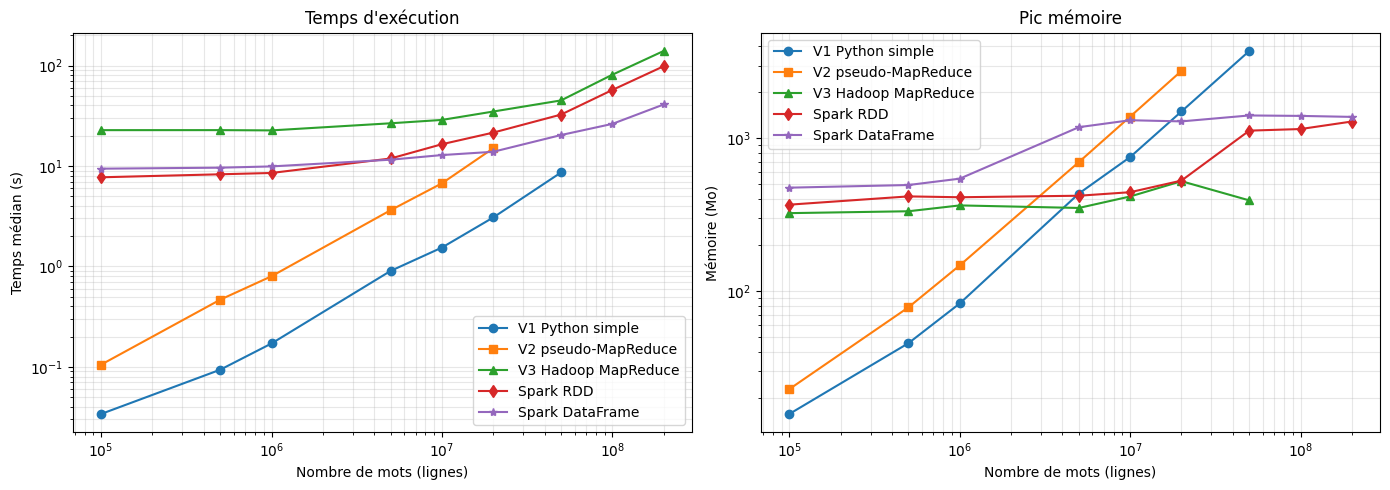

Méthode                 Coût fixe (s)   Coût par M de mots (s)
V1 Python simple                -0.05                    0.171
V2 pseudo-MapReduce             -0.05                    0.737
V3 Hadoop MapReduce             22.06                    0.583
Spark RDD                        9.78                    0.451
Spark DataFrame                 10.50                    0.155


In [34]:
# Rechargement de toutes les mesures depuis les CSV (indépendant de l'état du noyau)
lire = lambda nom: pd.read_csv(RESULTS / f"{nom}.csv")
df_ext = pd.read_csv(RESULTS / "extension.csv")
hadoop_ext = pd.DataFrame({"methode": "v3_hadoop", "m": df_ext["m"], "lignes": df_ext["lignes"],
                           "temps_median_s": df_ext["Hadoop temps (s)"], "statut": "ok"})

df_tout = pd.concat([lire("v1_python_simple"), lire("v2_pseudo_mapreduce"), lire("v3_hadoop"),
                     hadoop_ext, lire("spark_rdd"), lire("spark_dataframe")], ignore_index=True)
df_tout.to_csv(RESULTS / "comparaison_complete.csv", index=False)
ok2 = df_tout[df_tout["statut"] == "ok"]

STYLE2 = {"v1_python_simple":    ("V1 Python simple", "o-"),
          "v2_pseudo_mapreduce": ("V2 pseudo-MapReduce", "s-"),
          "v3_hadoop":           ("V3 Hadoop MapReduce", "^-"),
          "spark_rdd":           ("Spark RDD", "d-"),
          "spark_dataframe":     ("Spark DataFrame", "*-")}

temps = ok2.pivot(index="lignes", columns="methode", values="temps_median_s")[list(STYLE2)]
print("Temps médian (s)"); display(temps)
print("Pic mémoire (Mo)"); display(ok2.pivot(index="lignes", columns="methode",
                                            values="memoire_pic_Mo")[list(STYLE2)])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for methode, (label, style) in STYLE2.items():
    d = ok2[ok2["methode"] == methode].sort_values("lignes")
    ax1.plot(d["lignes"], d["temps_median_s"], style, label=label)
    ax2.plot(d["lignes"], d["memoire_pic_Mo"], style, label=label)
for ax, titre, ylabel in [(ax1, "Temps d'exécution", "Temps médian (s)"),
                          (ax2, "Pic mémoire", "Mémoire (Mo)")]:
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Nombre de mots (lignes)"); ax.set_ylabel(ylabel)
    ax.set_title(titre); ax.grid(True, which="both", alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(RESULTS / "comparaison_complete.png", dpi=150); plt.show()

print(f"{'Méthode':<22}{'Coût fixe (s)':>15}{'Coût par M de mots (s)':>25}")
for methode, (label, _) in STYLE2.items():
    d = ok2[ok2["methode"] == methode]
    pente, fixe = np.polyfit(d["lignes"], d["temps_median_s"], 1)
    print(f"{label:<22}{fixe:>15.2f}{pente * 1e6:>25.3f}")

### Analyse comparative des cinq méthodes
- **Spark contre Hadoop :** sur la même machine et les mêmes fichiers, Spark DataFrame est 3,4 fois plus rapide que Hadoop à 200 M de mots (40,9 s contre 139,6 s), et la version RDD 1,4 fois plus rapide. Trois raisons : les données intermédiaires restent en mémoire au lieu d'être écrites sur disque, les tâches ne relancent pas de JVM, et le parallélisme atteint 12 threads au lieu de 3 maps.
- **Spark contre la V1 (H5 réfutée) :** Spark ne devient pas plus rapide que la V1 dans le domaine où la V1 fonctionne. À 50 M de mots, la V1 met 8,6 s, contre 20,3 s pour Spark DataFrame lancé par `spark-submit` et 8,9 s à chaud. Leurs coûts par mot sont presque identiques (0,155 contre 0,171 s par million de mots). Le point de bascule extrapolé, environ 650 M de mots, se situe bien au-delà de la limite mémoire de la V1 (environ 87 M) : il est purement théorique.
- **Pourquoi 12 threads ne suffisent pas :**
  - avec seulement 15 mots distincts, la V1 se résume à un découpage en C et à un dictionnaire minuscule, ce qui est très efficace ;
  - Spark crée une ligne par mot (`explode`), puis l'agrège : ce surcoût par enregistrement absorbe le gain du parallélisme ;
  - le processeur hybride du portable (2 cœurs performants et 8 cœurs économes, sous WSL) limite le gain réel de 12 threads.
- **La hiérarchie dépend de la taille :**
  - jusqu'à environ 50 M de mots, la V1 est la plus rapide ;
  - au-delà, seules les méthodes à mémoire bornée fonctionnent, et parmi elles Spark DataFrame est nettement la plus rapide (environ 5 M de mots/s, contre 2 pour la version RDD et 1,4 pour Hadoop).

# Conclusion générale

### Synthèse des cinq méthodes

| Méthode | Coût fixe | Débit à grande échelle | Mémoire | Plus gros fichier traité |
|---|---|---|---|---|
| V1 Python simple | 17 ms | environ 6 M de mots/s | 75 o/mot, croissance linéaire | 50 M de mots (échec à 100 M) |
| V2 pseudo-MapReduce | 17 ms | environ 1,3 M de mots/s | 138 o/mot, croissance linéaire | 20 M de mots (échec à 50 M) |
| Hadoop MapReduce | 22,7 s | environ 1,4 M de mots/s | 0,3 à 0,5 Go par tâche, bornée | 200 M de mots ✔ |
| Spark RDD | 7,7 s | environ 2 M de mots/s | environ 1,2 Go, bornée | 200 M de mots ✔ |
| Spark DataFrame | 9,4 s (0,5 s à chaud) | environ 5 M de mots/s | environ 1,4 Go, bornée | 200 M de mots ✔ |

### Bilan des hypothèses
- **H1 et H3 validées :** coût fixe de Hadoop, surcoût mémoire de la V2.
- **H2 partiellement validée, H5 réfutée :** sur une seule machine, aucun moteur distribué ne devient plus rapide que le script Python simple tant que les données tiennent en mémoire.
- **H4 et H6 validées :** coût fixe de Spark intermédiaire entre Python et Hadoop ; version DataFrame plus rapide que la version RDD sur les gros volumes (mais pas sur les petits).

### Ce qu'il faut retenir
1. **Sur une seule machine, un moteur distribué n'apporte pas la vitesse, mais la capacité.** Hadoop et Spark traitent des volumes qui dépassent la mémoire, grâce au découpage des données et à l'agrégation locale (combiner, `reduceByKey`).
2. **Parmi les solutions qui passent à l'échelle, Spark surclasse Hadoop MapReduce :** coût fixe divisé par 2,5, débit multiplié par 3,4 avec l'API DataFrame, et un mode interactif qui supprime presque le coût de démarrage. C'est pourquoi Spark a remplacé MapReduce dans la plupart des usages actuels, souvent en s'appuyant sur HDFS et YARN.
3. **L'API compte autant que le moteur :** à moteur égal, la version DataFrame est 2,4 fois plus rapide que la version RDD, car elle laisse Spark optimiser le calcul et évite le passage par Python.

### Quel outil choisir ?
- **Les données tiennent en mémoire d'une machine :** un script Python, idéalement en lecture en flux.
- **Les données dépassent la mémoire, sur une seule machine :** Spark DataFrame en mode local.
- **Les données dépassent une machine, ou le traitement doit tolérer des pannes :** Spark sur un cluster. Hadoop MapReduce reste surtout utile pour comprendre le modèle, et pour les systèmes existants.

### Limites
- Une seule machine, un portable sous WSL2 : aucun parallélisme entre nœuds.
- Vocabulaire de 15 mots, très favorable à la V1 et aux agrégations locales.
- Conditions légèrement différentes entre les sessions : V1 et V2 mesurées avec les services Hadoop actifs, Spark avec Hadoop arrêté. La variabilité entre sessions atteint 30 % sur certains points : seuls les écarts importants sont interprétés.